# Part 4: Báo Cáo Mã Hóa Biến Phân Loại & Chuẩn Hóa Đặc Trưng (Encoding & Normalization)
**Thành viên phụ trách:** Phan Thanh Tú | **Nhánh Git:** `feature/encoding-normalization`
---
Notebook thực hiện và kiểm định quy trình Tiền xử lý dữ liệu (Mã hóa One-Hot & Chuẩn hóa StandardScaler):
1. **Cô lập rò rỉ dữ liệu (Zero-leakage):** Loại bỏ hoàn toàn 4 cột rò rỉ (`delay_min`, `actual_time`, `status`, `status_detail`).
2. **Mã hóa OneHotEncoder:** Áp dụng `handle_unknown='ignore'` cho 5 biến phân loại (`airline_code`, `airport`, `direction`, `route_type`, `carrier_category`).
3. **Chuẩn hóa StandardScaler:** Đưa các biến số liên tục (`airport_load`, `precipitation`, `weather_hazard_score`, chu kỳ sin/cos giờ bay) về thang đo chuẩn N(0, 1).
4. **Giữ nguyên biến nhị phân:** Duy trì 14 cờ chỉ thị nhị phân (`is_peak_hour`, `is_rain`, `is_storm`, `is_golden_triangle`...).
5. **Đóng gói và lưu trữ Transformer:** Xuất `encoder.joblib`, `scaler.joblib`, `preprocessing_metadata.json` phục vụ suy luận mô hình.
*(Lưu ý: Phần chia tập dữ liệu Train/Test theo ngày được bàn giao cho Thành viên 5 thực hiện trong Part 5).*


### 1. Thực Thi Mã Hóa, Chuẩn Hóa & Kiểm Định Chống Rò Rỉ Dữ Liệu


In [ ]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import pandas as pd
from modeling.encoding import (
    FlightDataPreprocessor, LEAKAGE_COLUMNS, CATEGORICAL_COLS,
    NUMERIC_CONTINUOUS_COLS, PASSTHROUGH_BINARY_COLS, PROCESSED_DIR
)
from features.features import run_feature_pipeline

# 1. Đọc dữ liệu đặc trưng từ Part 3
features_path = PROCESSED_DIR / 'flights_features.csv'
if not features_path.exists():
    df = run_feature_pipeline()
else:
    df = pd.read_csv(features_path)

print(f'Dữ liệu đầu vào: {df.shape[0]:,} dòng x {df.shape[1]} cột')

preprocessor = FlightDataPreprocessor()
preprocessor.fit(df)
X_transformed = preprocessor.transform(df)
X_df = preprocessor.to_dataframe(X_transformed)

print('\n=== KIỂM ĐỊNH RÒ RỈ DỮ LIỆU (ZERO-LEAKAGE CHECK) ===')
for col in LEAKAGE_COLUMNS:
    assert col not in X_df.columns, f'Cảnh báo: Cột rò rỉ {col} xuất hiện trong X!'
print('XÁC NHẬN: 100% không rò rỉ dữ liệu (delay_min, actual_time, status đã được loại bỏ).')

preprocessor.save(PROCESSED_DIR)
print(f'\nĐã lưu trữ transformer thành công vào {PROCESSED_DIR}:')
print(f'- encoder.joblib ({len(preprocessor.encoded_cat_names)} cột danh mục sau OneHot)')
print(f'- scaler.joblib ({len(NUMERIC_CONTINUOUS_COLS)} cột chuẩn hóa StandardScaler)')
print(f'- preprocessing_metadata.json (Tổng số đặc trưng: {len(preprocessor.feature_names)})')
print(f'Kích thước ma trận đặc trưng hoàn chỉnh: {X_df.shape[0]:,} dòng x {X_df.shape[1]} cột')


In [ ]:
print(df[CATEGORICAL_COLS].nunique())
print("Số cột One-Hot:", len(preprocessor.encoded_cat_names))
print("Tổng đặc trưng:", len(preprocessor.feature_names))


In [ ]:
X_df[NUMERIC_CONTINUOUS_COLS].describe().loc[["mean", "std"]].round(3)

In [ ]:
t = df.head(3).copy()
t["airline_code"] = "ZZZ_NEW"
out = preprocessor.transform(t)
idx = [i for i, c in enumerate(preprocessor.feature_names) if c.startswith("airline_code_")]
print("Shape:", out.shape, "| Tổng cột airline_code:", out[:, idx].sum())

# 4.1. Kỹ thuật Mã hóa biến Phân loại và Chuẩn hóa Thang đo Đặc trưng

## 4.1.1. Mục tiêu
Sau bước Kỹ nghệ đặc trưng (Part 3), tập dữ liệu có 46 cột gồm biến danh mục dạng chữ, biến số liên tục có thang đo chênh lệch lớn và các cờ nhị phân. Lớp `FlightDataPreprocessor` thực hiện bốn việc: cô lập rò rỉ dữ liệu, mã hóa One-Hot, chuẩn hóa StandardScaler và giữ nguyên các cờ nhị phân.

## 4.1.2. Cô lập rò rỉ dữ liệu (Data Leakage Guard)
Bốn cột `delay_min`, `actual_time`, `status`, `status_detail` chỉ được biết sau khi chuyến bay kết thúc. Nếu đưa vào ma trận đặc trưng X, mô hình sẽ "nhìn trước đáp án" và cho kết quả cao giả tạo. Các cột này cùng các mã định danh (`leg_key`, `flight_no`, `origin`, `destination`, ...) bị loại hoàn toàn. Lớp `FlightDataPreprocessor` chỉ chọn 5 biến danh mục, 10 biến liên tục và 14 cờ nhị phân, nên các cột còn lại không thể lọt vào.

Kiểm định: notebook dùng `assert` để xác nhận không cột rò rỉ nào xuất hiện trong X, và test `test_zero_leakage_in_training_features` báo OK.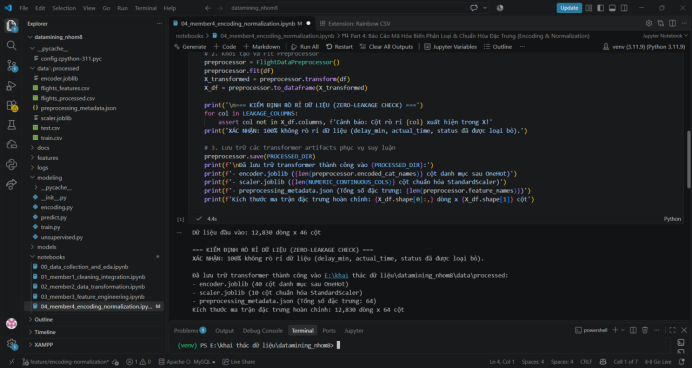

## 4.1.3. Mã hóa One-Hot
Năm biến danh mục được mã hóa bằng `OneHotEncoder(handle_unknown="ignore")`:

| Biến danh mục | Số giá trị | Số cột One-Hot |
|---|---|---|
| airline_code | 7 | 7 |
| airport | 23 | 23 |
| direction | 2 | 2 |
| route_type | 2 | 2 |
| carrier_category | 6 | 6 |
| **Tổng** | **40** | **40** |

Ghép với 10 cột liên tục và 14 cờ nhị phân, ma trận đặc trưng cuối cùng có **64 chiều**.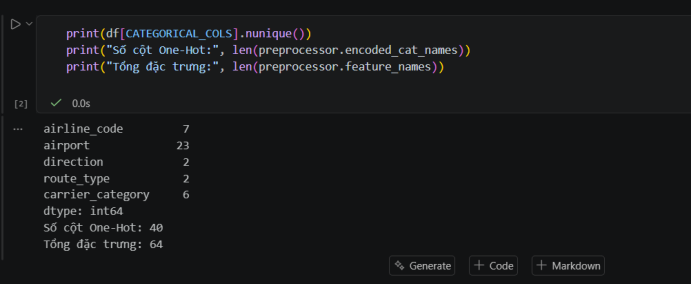

## 4.1.4. Chuẩn hóa StandardScaler
Mười biến liên tục có thang đo rất khác nhau (tầm nhìn khoảng 10.000 m, gió khoảng 60 km/h, mưa khoảng 20 mm). StandardScaler đưa mỗi biến về phân phối chuẩn N(0, 1):

$$z = \frac{x - \mu}{\sigma}$$

trong đó x là giá trị gốc, μ là trung bình và σ là độ lệch chuẩn trên tập huấn luyện. Sau chuẩn hóa, trung bình xấp xỉ 0 và độ lệch chuẩn xấp xỉ 1.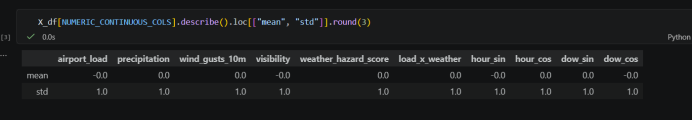

## 4.1.5. Giữ nguyên các cờ nhị phân
Các cờ như `is_peak_hour`, `is_rain`, `is_storm`, `is_golden_triangle`, ... đã có giá trị 0/1 nên được giữ nguyên (passthrough), không mã hóa hay chuẩn hóa thêm để bảo toàn ý nghĩa.

## 4.1.6. Cơ chế chống crash khi gặp giá trị mới
Nhờ `handle_unknown="ignore"`, khi gặp hãng bay hoặc sân bay chưa từng thấy, bộ tiền xử lý gán toàn bộ vector 0 thay vì báo lỗi. Thử nghiệm với mã hãng giả `ZZZ_NEW` cho kết quả không lỗi và tổng các cột `airline_code` bằng 0.

## 4.1.7. Chỉ fit trên tập Train
Encoder và scaler chỉ học trên 80% dữ liệu đầu theo thời gian (10.264 chuyến, cutoff 2026-10-30), rồi áp dụng cho tập Test (2.566 chuyến). Cách này ngăn thông tin của tập Test lọt vào quá trình chuẩn hóa.